In [2]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [3]:
from pathlib import Path

current = Path.cwd()

matches = list(current.glob("**/WA_Fn-UseC_-Telco-Customer-Churn.csv"))

if not matches:
    matches = list(current.parent.glob("**/WA_Fn-UseC_-Telco-Customer-Churn.csv"))

if matches:
    DATA_PATH = matches[0]
    print("Dataset found:", DATA_PATH)
else:
    print("Dataset not found. Check where you extracted the CSV.")


Dataset found: D:\Meet_PrimeAIML\Supervised ML\Projects\Telecom-Customer-Churn-Prediction\Data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv


In [4]:
import pandas as pd

df = pd.read_csv(DATA_PATH)
display(df.head())
print("Dataset shape:", df.shape)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape: (7043, 21)


In [5]:
# EDA 
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.sample(5,random_state=42)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
# Count customers who churned and stayed
print(df["Churn"].value_counts())

# Calculate the percentage of each class
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


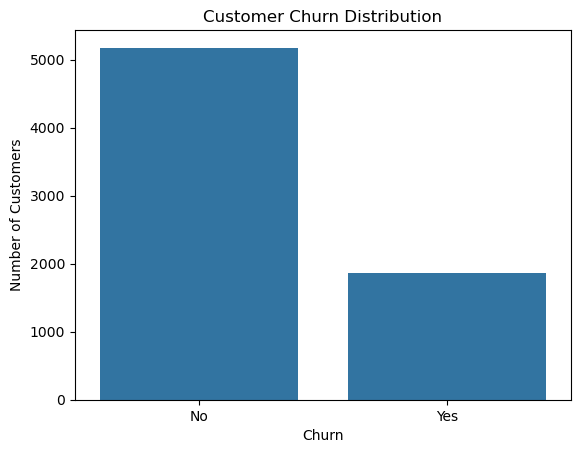

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()


In [12]:
print(df["TotalCharges"].dtype)

print(
    df.loc[
        df["TotalCharges"].str.strip() == "",
        ["customerID", "tenure", "TotalCharges"]
    ].head(10)
)

print(
    "Blank TotalCharges:",
    (df["TotalCharges"].str.strip() == "").sum()
)

object
      customerID  tenure TotalCharges
488   4472-LVYGI       0             
753   3115-CZMZD       0             
936   5709-LVOEQ       0             
1082  4367-NUYAO       0             
1340  1371-DWPAZ       0             
3331  7644-OMVMY       0             
3826  3213-VVOLG       0             
4380  2520-SGTTA       0             
5218  2923-ARZLG       0             
6670  4075-WKNIU       0             
Blank TotalCharges: 11


In [13]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [14]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [15]:
df.loc[
    df["TotalCharges"].isnull(),
    ["customerID", "tenure", "TotalCharges", "Churn"]
]

,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,NaN,No
753,3115-CZMZD,0,NaN,No
936,5709-LVOEQ,0,NaN,No
1082,4367-NUYAO,0,NaN,No
1340,1371-DWPAZ,0,NaN,No
3331,7644-OMVMY,0,NaN,No
3826,3213-VVOLG,0,NaN,No
4380,2520-SGTTA,0,NaN,No
5218,2923-ARZLG,0,NaN,No
6670,4075-WKNIU,0,NaN,No


In [16]:
df.loc[df["TotalCharges"].isnull(), "TotalCharges"] = 0

In [17]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [18]:

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

display(contract_churn)


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83



Churn rate by gender


Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16


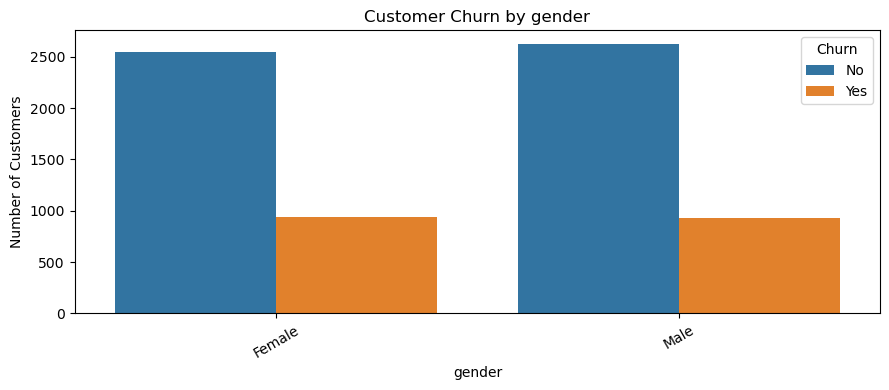


Churn rate by Partner


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


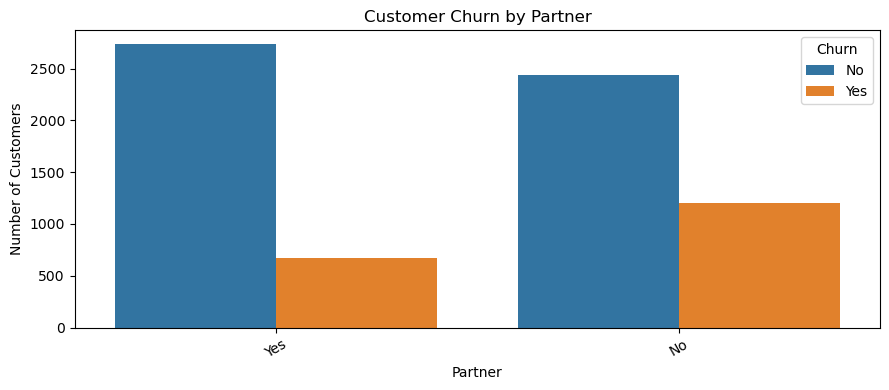


Churn rate by Dependents


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


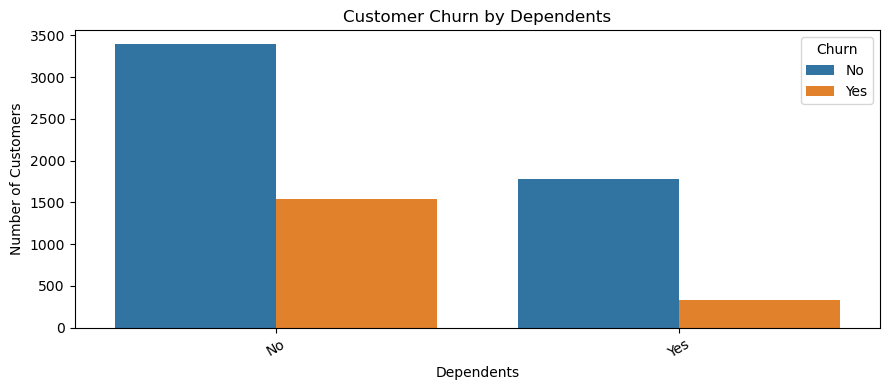


Churn rate by PhoneService


Churn,No,Yes
PhoneService,,
No,75.07,24.93
Yes,73.29,26.71


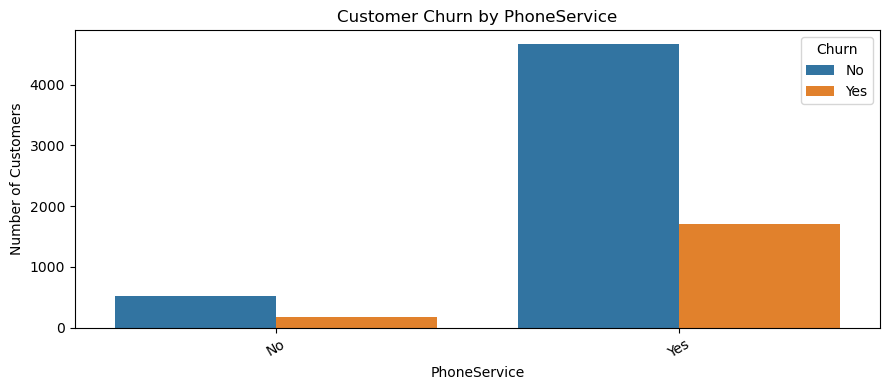


Churn rate by MultipleLines


Churn,No,Yes
MultipleLines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61


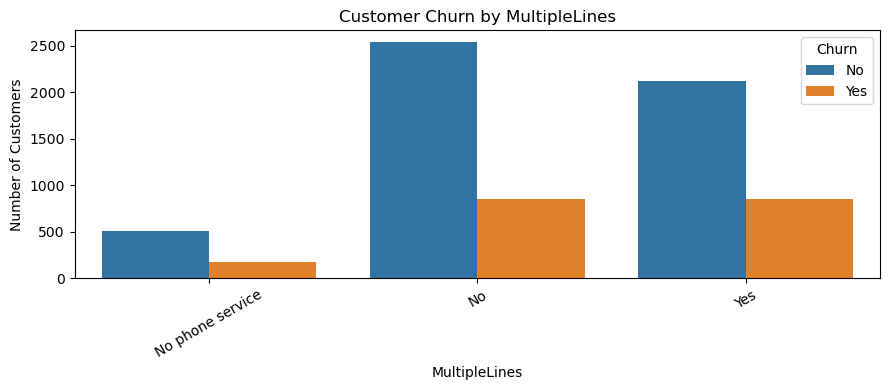


Churn rate by InternetService


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


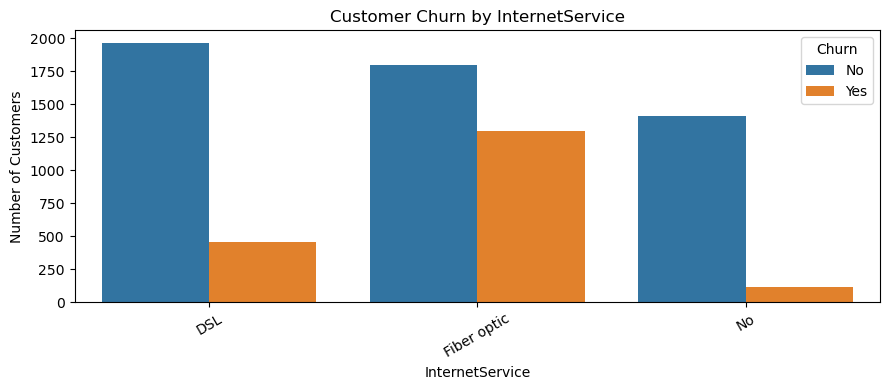


Churn rate by OnlineSecurity


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


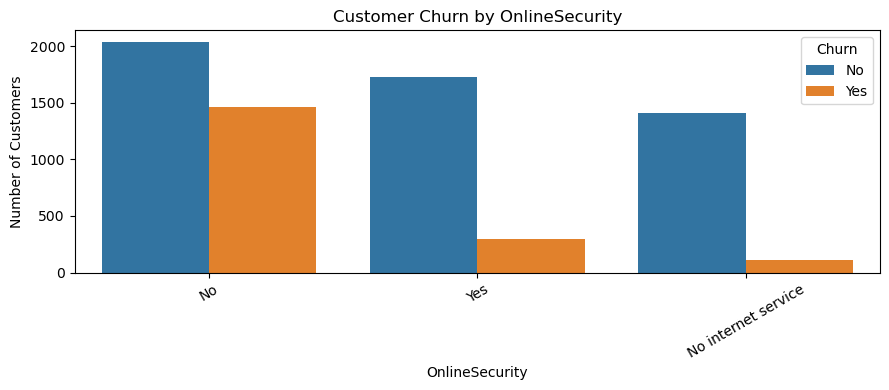


Churn rate by OnlineBackup


Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


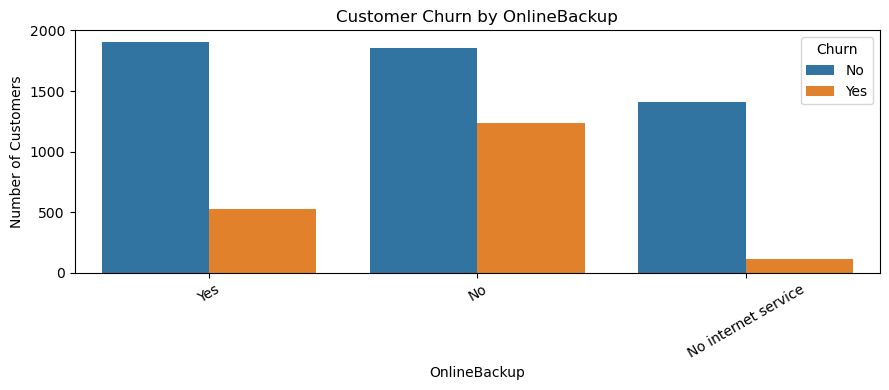


Churn rate by DeviceProtection


Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


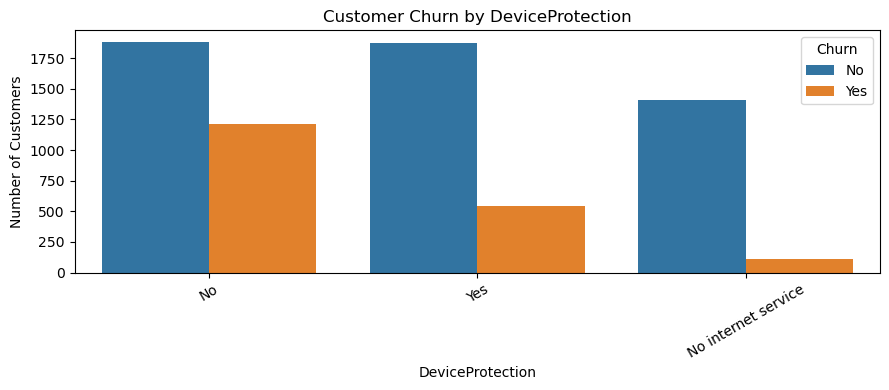


Churn rate by TechSupport


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


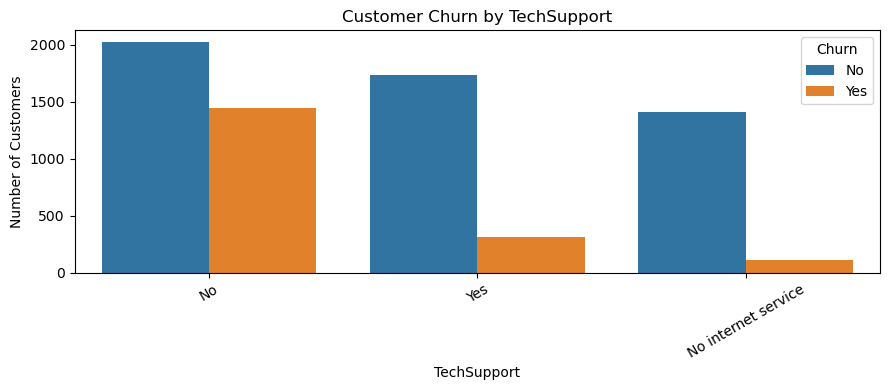


Churn rate by StreamingTV


Churn,No,Yes
StreamingTV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07


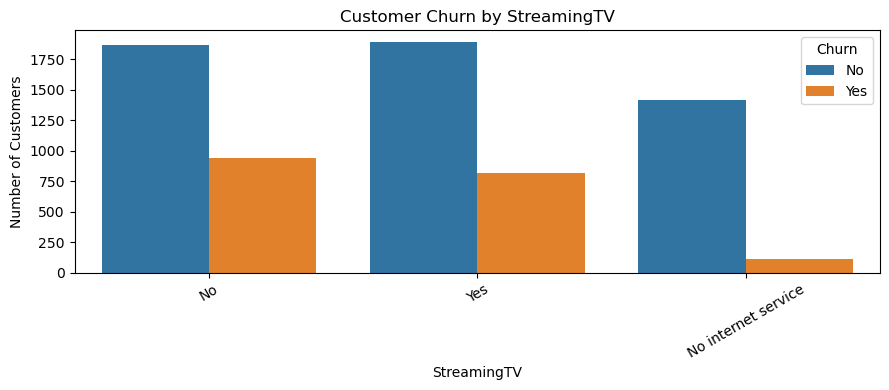


Churn rate by StreamingMovies


Churn,No,Yes
StreamingMovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


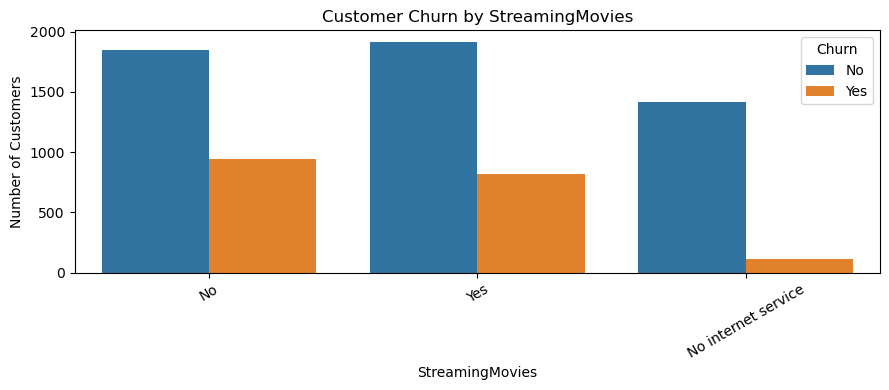


Churn rate by Contract


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


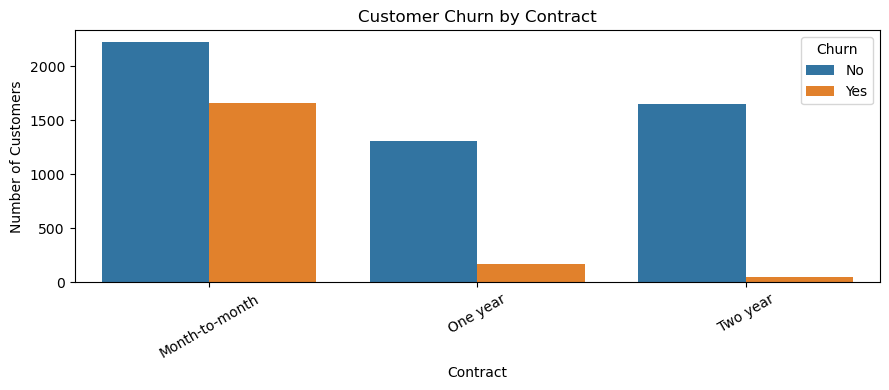


Churn rate by PaperlessBilling


Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


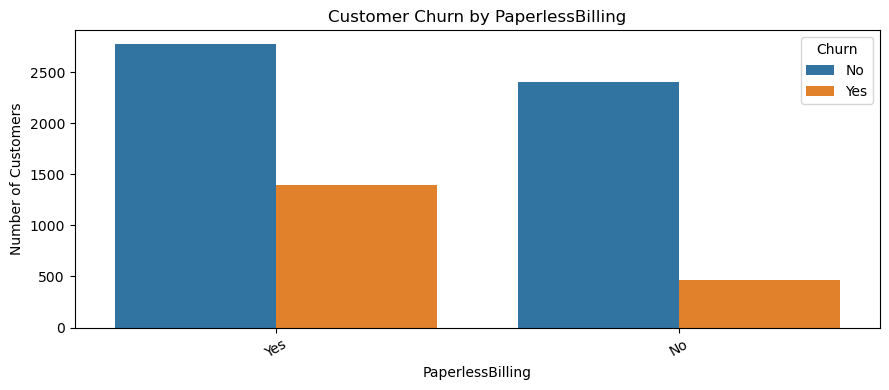


Churn rate by PaymentMethod


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


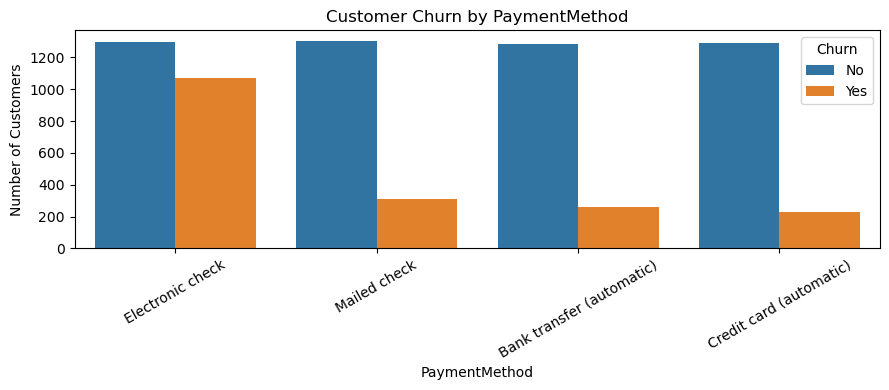

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select categorical columns, excluding ID and target
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.drop(
    ["customerID", "Churn"],
    errors="ignore"
)

for col in categorical_cols:
    print(f"\n{'=' * 50}")
    print(f"Churn rate by {col}")
    print("=" * 50)

    # Churn percentage within each category
    churn_rate = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ).mul(100).round(2)

    display(churn_rate)

    # Visualize customer counts
    plt.figure(figsize=(9, 4))
    sns.countplot(data=df, x=col, hue="Churn")
    plt.title(f"Customer Churn by {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80



Analyzing tenure


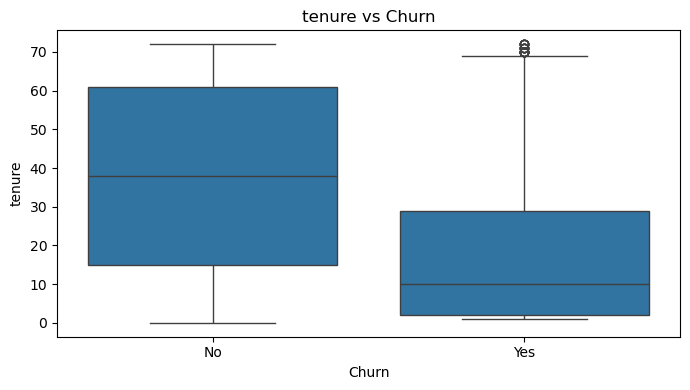


Analyzing MonthlyCharges


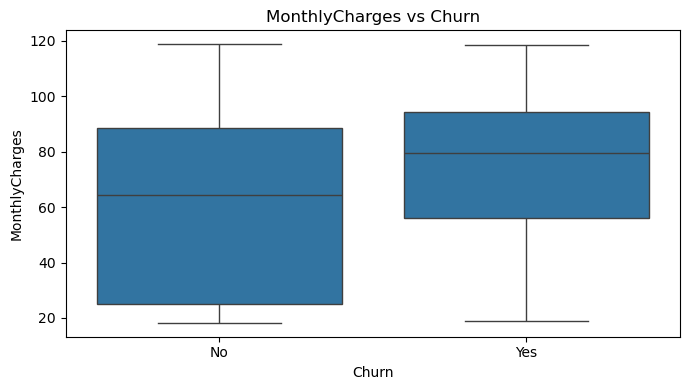


Analyzing TotalCharges


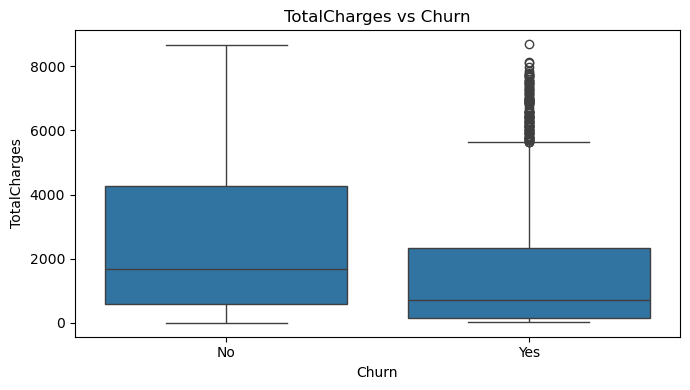


Churn rate by SeniorCitizen


Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


In [20]:
# Select numerical columns, excluding binary SeniorCitizen from box plots
numerical_cols = df.select_dtypes(include="number").columns.drop(
    ["SeniorCitizen"],
    errors="ignore"
)

# Summary statistics
display(df[numerical_cols].describe().round(2))

# Compare numerical features against churn
for col in numerical_cols:
    print(f"\nAnalyzing {col}")

    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Churn", y=col)
    plt.title(f"{col} vs Churn")
    plt.xlabel("Churn")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

# Analyze SeniorCitizen separately because it is binary
print("\nChurn rate by SeniorCitizen")
display(
    pd.crosstab(
        df["SeniorCitizen"],
        df["Churn"],
        normalize="index"
    ).mul(100).round(2)
)


In [21]:
# Check the current dataset
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget values:")
print(df["Churn"].value_counts(dropna=False))

print("\nData types:")
print(df.dtypes)


Dataset shape: (7043, 21)

Missing values:
Series([], dtype: int64)

Duplicate rows: 0

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [22]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [25]:
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include="number"
).columns.tolist()

print("Categorical features:", categorical_features)
print("\nNumerical features:", numerical_features)

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_transformer = Pipeline([
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing setup completed.")

Preprocessing setup completed.
